<a href="https://colab.research.google.com/github/Mukundan-T/seqADAGE/blob/main/Py/muk_uADAGE/BaselineEcoliModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Baseline E. coli Models

### By: Mukundan Thanigaivelan

### September 22, 2026

In this notebook, we will be training baseline E. coli models with the standard ADAGE loss function (mean squared error) with **no regularizer** as control models.

## 0. Connect to GitHub

In [5]:
!git clone https://github.com/Mukundan-T/seqADAGE.git

Cloning into 'seqADAGE'...
remote: Enumerating objects: 995, done.
remote: Counting objects: 100% (217/217), done.
remote: Compressing objects: 100% (146/146), done.
remote: Total 995 (delta 166), reused 77 (delta 71), pack-reused 778 (from 2)
Receiving objects: 100% (995/995), 59.85 MiB | 33.69 MiB/s, done.
Resolving deltas: 100% (585/585), done.


In [6]:
%cd seqADAGE/Py/muk_uADAGE

/content/seqADAGE/Py/muk_uADAGE


In [7]:
!pip install -qq tensorflow keras statsmodels seaborn keras_tuner

## 1. Loading classes & modules

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

In [10]:
# ADAGE
from adage import Adage as ad, SeqAdage, LinkedAE

# Data Analysis
import pandas as pd
import numpy as np
import keras

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Miscellaneous
import zipfile
import time
import json
import tensorflow as tf
from types import SimpleNamespace

In [11]:
# check CPU and GPU available in runtime
print("Num CPUs Available: ", len(tf.config.list_physical_devices('CPU')))
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
print(tf.test.is_built_with_cuda())

Num CPUs Available:  1
Num GPUs Available:  1
True


## 2. Unregularized E. coli ADAGE

Hyperparameter search results:

* Units: 60
* Dropout: 0
* Activation 1: CeLU
* Activation 2: CeLU
* Shuffle: False
* Initialization: glorot_normal
* kl1: 0
* kl2: 0
* lr: 0.031
* bs: 15
* mm: 0.30000000000000004

### 2a. Find and save optimal model hyperparameters

In [12]:
# Load filtered and re-normalized data
filename = '/content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ecmg_lcn01_medmean_normal_muk.csv'

filtered_df = pd.read_csv(filename, index_col = 0)
filtered_df.shape

(3608, 10233)

In [13]:
# Find optimal hyperparameter values
model_trainer = SeqAdage.SeqAdage(filename)
best_hps, tuner = model_trainer.tune_model(
  seed = 42,
  k1 = [0, 0, 0.1],
  k2 = [0, 0, 0.1],
  d = [0, 0, 0.1]
)

Trial 90 Complete [00h 00m 40s]
val_loss: 0.01107612531632185

Best val_loss So Far: 0.007712018210440874
Total elapsed time: 00h 23m 39s
Results summary
Results in /content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ecmg_lcn01_medmean_normal_muk_42
Showing 10 best trials
Objective(name="val_loss", direction="min")

Trial 0051 summary
Hyperparameters:
units: 20
dropout: 0.0
act1: celu
shuffle: True
init: glorot_normal
kl1: 0.0
kl2: 0.0
lr: 0.07100000000000001
bs: 10
mm: 0.4
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 3
tuner/round: 3
tuner/trial_id: 0046
Score: 0.007712018210440874

Trial 0050 summary
Hyperparameters:
units: 50
dropout: 0.0
act1: celu
shuffle: True
init: glorot_normal
kl1: 0.0
kl2: 0.0
lr: 0.011
bs: 5
mm: 0.7000000000000001
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 3
tuner/round: 3
tuner/trial_id: 0049
Score: 0.008410823531448841

Trial 0082 summary
Hyperparameters:
units: 60
dropout: 0.0
act1: celu
shuffle: False
init: glorot_norma

In [36]:
# Optimal hyperparameters - decide based on higher value of units and batch size (bs)
hps = best_hps[2].values
hps

{'units': 60,
 'dropout': 0.0,
 'act1': 'celu',
 'shuffle': False,
 'init': 'glorot_normal',
 'kl1': 0.0,
 'kl2': 0.0,
 'lr': 0.031,
 'bs': 15,
 'mm': 0.30000000000000004,
 'tuner/epochs': 50,
 'tuner/initial_epoch': 17,
 'tuner/bracket': 1,
 'tuner/round': 1,
 'tuner/trial_id': '0075'}

In [37]:
# Save optimal model hyperparameters
hps['act1/act2'] = hps.pop('act1')
optimal_hps = {param: val for param, val in hps.items() if not param.startswith('tuner')}
with open('/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/ec_control_model_hps.json', "w") as f:
  json.dump(optimal_hps, f)

### 2b. Train, choose, and save optimal models

In [ ]:
# Load hyperparameters
with open('/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/ec_control_model_hps.json', 'r') as f:
  optimal_hps = json.load(f)

# Train models
control_models = {}
ec_objs = []
seeds = list(range(75))

for seed in seeds:
  sa = SeqAdage.SeqAdage(
    filename,
    seed = seed + 100,
    enc_dim = optimal_hps['units'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    act = optimal_hps['act1/act2'],
    act2 = optimal_hps['act1/act2'],
    epochs = 50,
    init = optimal_hps['init'],
    batch_size = optimal_hps['bs'],
    dropout = optimal_hps['dropout'],
    mm = optimal_hps['mm'],
    lr = optimal_hps['lr']
  )
  sa.train_model()
  temp = ad.Adage(sa.autoencoder, sa.history, sa.all_comp)

  ec_objs.append(sa)
  control_models[seed] = temp
  print(f'\nFinished {seed+1}/{len(seeds)}\n')

In [39]:
# Create enrichment dataframes
kegg_dfs = {}

for seed in control_models.keys():
  ec_kegg_ps = control_models[seed].set_kegg(
    '/content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ec_kegg_pathways.txt'
  )
  kegg_dfs[seed] = ec_kegg_ps

In [40]:
# Save sum of p-values and pathways to lists
p_val_sums = []
path_info = []

for df in kegg_dfs.values():
  p_val_sums.append(df.sum().sum())
  path_info.append(df.columns[(df > 1.5).any()].tolist())

In [41]:
# Inspect p-values
p_val_sums

[np.float64(407.4087250382359),
 np.float64(505.91918507832963),
 np.float64(432.9824537926471),
 np.float64(385.2359383509491),
 np.float64(540.3298097506207),
 np.float64(472.55885963211836),
 np.float64(309.38409301893523),
 np.float64(726.7734306974015),
 np.float64(508.7801318167764),
 np.float64(518.0093891516627),
 np.float64(366.9414123538555),
 np.float64(530.4414534917464),
 np.float64(480.06521039185174),
 np.float64(461.0218809400983),
 np.float64(563.8251584280881),
 np.float64(487.7145558128438),
 np.float64(493.2278255778259),
 np.float64(500.36939507579643),
 np.float64(465.1415685739575),
 np.float64(455.8760738813499),
 np.float64(454.7577283854423),
 np.float64(576.3440135016913),
 np.float64(357.474462540957),
 np.float64(311.3837498680057),
 np.float64(556.8980018960358),
 np.float64(649.3965111818324),
 np.float64(582.8259488043727),
 np.float64(588.399181541303),
 np.float64(596.8898045025437),
 np.float64(452.5436029470279),
 np.float64(559.0725399524358),
 np.f

In [42]:
# Save all 75 models
for seed in seeds:
  ec_objs[seed].autoencoder.save(
    f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/ec_best_model{seed+1}.keras'
  )

In [43]:
# Save training/validation loss history
for seed in seeds:
  for loss_type in ['loss', 'val_loss']:
    np.savetxt(
      f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/loss_history/ec_control_{loss_type}_model{seed+1}.csv',
      ec_objs[seed].history.history[loss_type],
      delimiter=','
    )

In [44]:
# Save KEGG enrichment matrices for all models
for seed in seeds:
  kegg_dfs[seed].to_csv(
    f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/kegg_dfs/ec_kegg_ps{seed+1}.csv',
  )

### 2c. Load optimal models

In [45]:
model_filenames = [
  f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/ec_best_model{i+1}.keras'
  for i in range(10)
]

In [46]:
# Load hyperparameters
with open('/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/ec_control_model_hps.json', 'r') as f:
  optimal_hps = json.load(f)

In [47]:
loaded_models = []

for i, file in enumerate(model_filenames):
  # Create autoencoder object
  ae = LinkedAE.LinkedAE(
    encoding_dim = optimal_hps['units'],
    act1 = optimal_hps['act1/act2'],
    d = optimal_hps['dropout'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    init = optimal_hps['init']
  )
  ae(tf.zeros((1, filtered_df.shape[0])))

  # Pull model weights
  with zipfile.ZipFile(file) as z:
    z.extract('model.weights.h5')

  # Load saved weights
  ae.load_weights('model.weights.h5')

  # Create ADAGE object
  adage = ad.Adage(
    autoencoder = ae,
    history = SimpleNamespace(
      history = {
        'loss': np.loadtxt(
                  f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/loss_history/ec_control_loss_model{i+1}.csv',
                  delimiter=','
                ).reshape(-1).tolist(),
        'val_loss': np.loadtxt(
                      f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/loss_history/ec_control_val_loss_model{i+1}.csv',
                      delimiter=','
                    ).reshape(-1).tolist()
      }
    ),
    train_comp = pd.read_csv(
      '/content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ecmg_lcn01_medmean_normal_muk.csv',
      index_col = 0
    )
  )

  # Add model to list
  loaded_models.append(adage)

### 2d. Loss curves and weight distributions

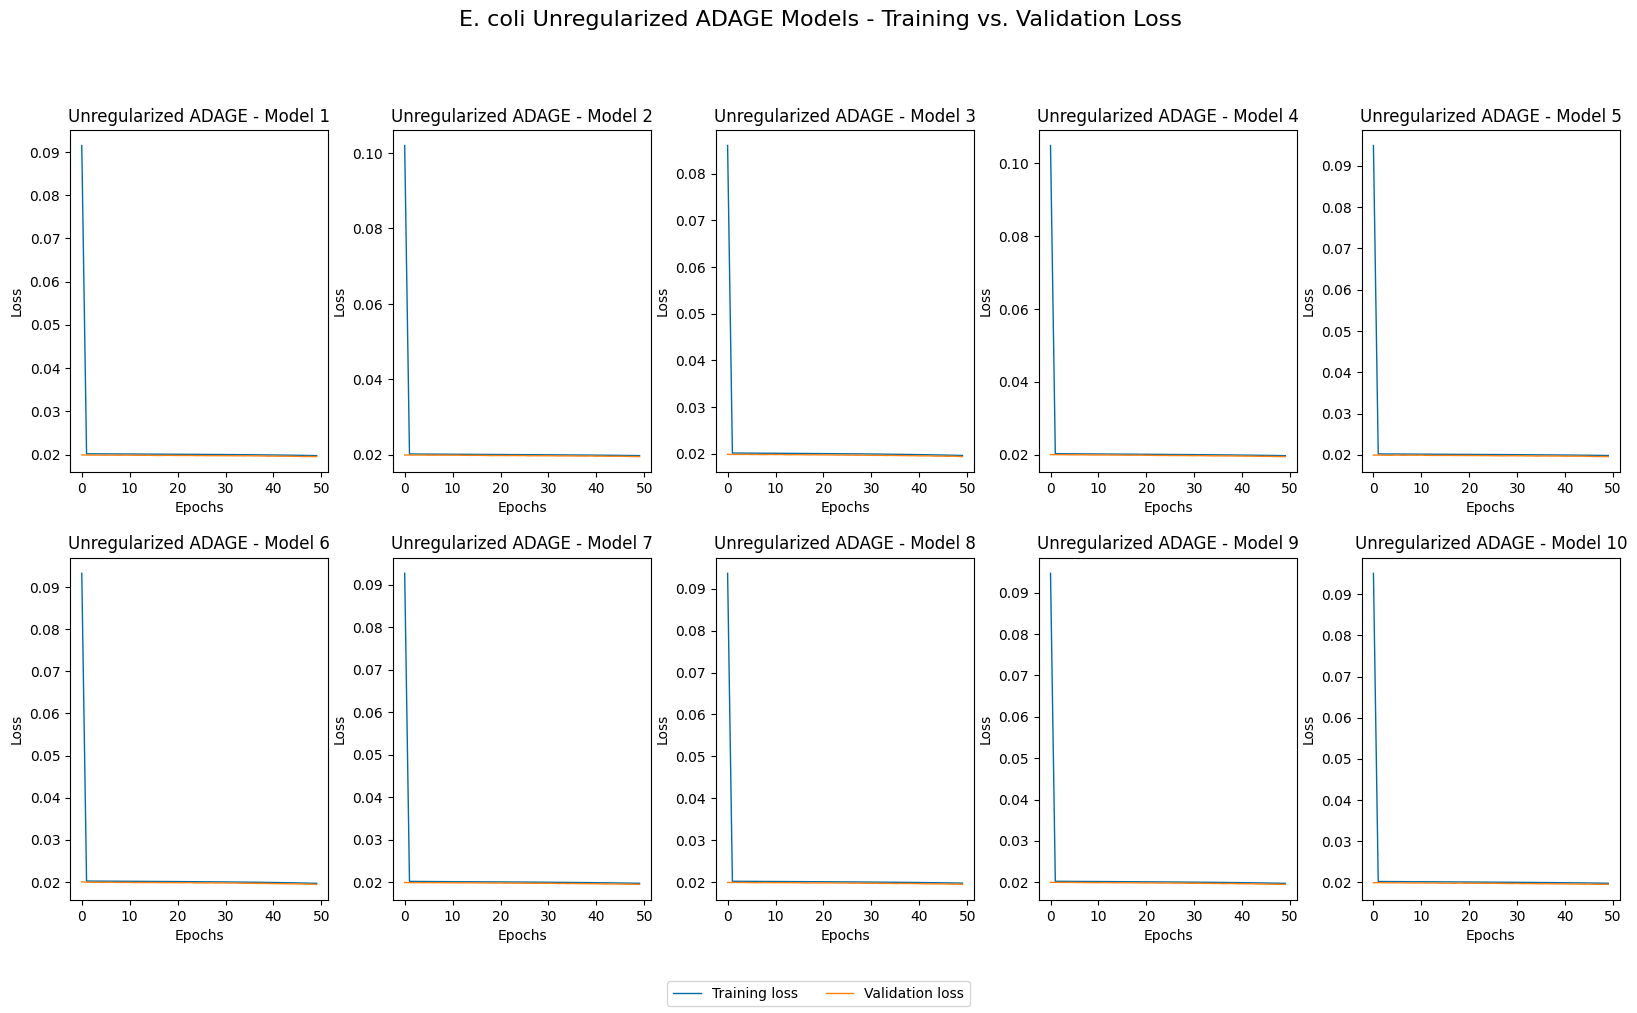

In [51]:
plot_titles = [
  f'Unregularized ADAGE - Model {i+1}'
  for i in range(10)
]
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots(2, 5, figsize = (20, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli Unregularized ADAGE Models - Training vs. Validation Loss',
  fontsize = 16,
  y = 1
)

for i in range(2):
  for j in range(5):
    ax[i, j].plot(
      range(50),
      loaded_models[5*i + j].history.history['loss'],
      linewidth = 1,
      label = 'Training loss'
    )
    ax[i, j].plot(
      range(50),
      loaded_models[5*i + j].history.history['val_loss'],
      linewidth = 1,
      label = 'Validation loss'
    )
    ax[i, j].set(
      title = plot_titles[5*i + j],
      xlabel = 'Epochs',
      ylabel = 'Loss'
    )

handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(
  handles,
  labels,
  loc = 'lower center',
  ncol = 2,
  fontsize = 10
)

fig.savefig(
  '/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/Plots/ec_control_loss.png',
  dpi = 300,
  bbox_inches = 'tight'
)

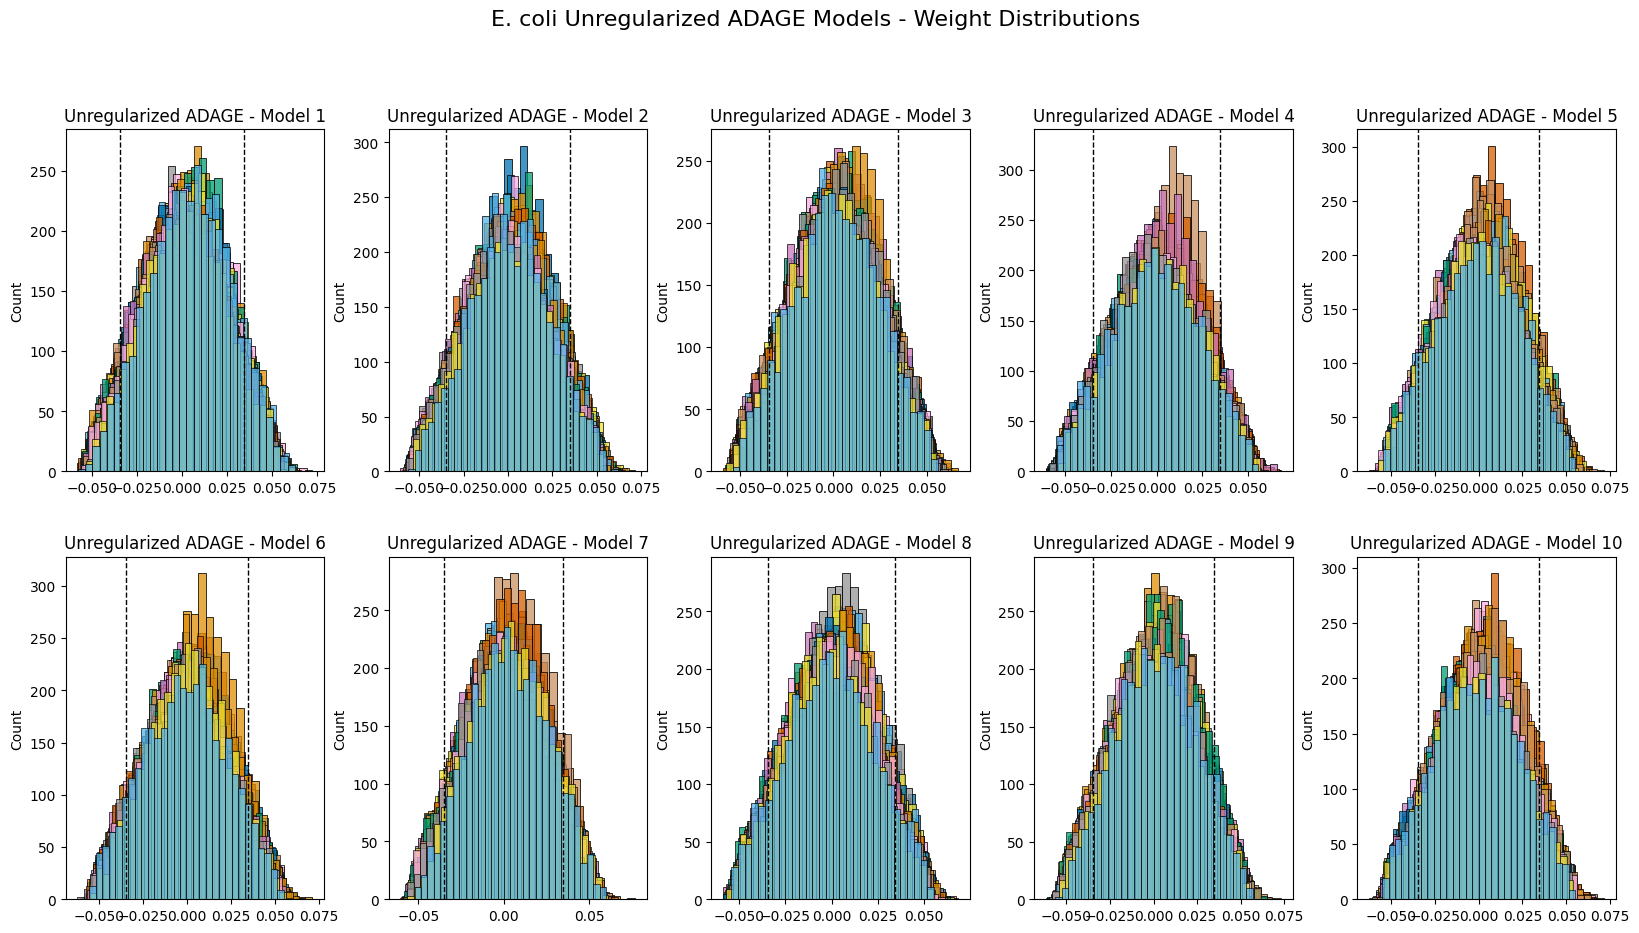

In [53]:
plot_titles = [
  f'Unregularized ADAGE - Model {i+1}'
  for i in range(10)
]

fig, ax = plt.subplots(2, 5, figsize = (20, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli Unregularized ADAGE Models - Weight Distributions',
  fontsize = 16,
  y = 1
)
colorblind_colors = sns.color_palette("colorblind")

for i in range(2):
  for j in range(5):
    weights_matrix = np.asarray(loaded_models[5*i + j].autoencoder.get_weights()[0])

    for node in range(optimal_hps['units']):
      weights = weights_matrix[:, node]
      weights = weights[np.isfinite(weights)]

      # Skip empty arrays and constant distributions
      if len(weights) == 0 or np.min(weights) == np.max(weights):
        continue

      # Each hidden node weight distribution
      sns.histplot(
        weights,
        ax = ax[i, j],
        bins = 30,
        color = colorblind_colors[node % len(colorblind_colors)],
        kde = False
      )

    all_weights = weights_matrix.flatten()
    all_weights = all_weights[np.isfinite(all_weights)]
    cutoff = np.std(all_weights) * 1.5

    ax[i, j].axvline(
        x = cutoff,
        color = 'black',
        linestyle = '--',
        linewidth = 1
    )
    ax[i, j].axvline(
        x = -cutoff,
        color = 'black',
        linestyle = '--',
        linewidth = 1
    )
    ax[i, j].set(title = plot_titles[5*i + j])

fig.savefig(
  '/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/Plots/ec_control_weight_dists.png',
  dpi = 300,
  bbox_inches = 'tight'
)

### 2e. Perform KEGG analysis

In [54]:
# Load KEGG p-value matrices
kegg_ps = [
  pd.read_csv(
    f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/kegg_dfs/ec_kegg_ps{i+1}.csv'
  )
  for i in range(75)
]

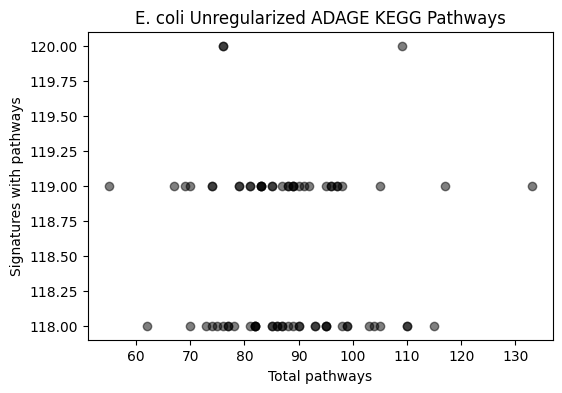

In [55]:
# Plot KEGG pathways
plt.figure(figsize = (6, 4))

for kegg_vals in kegg_ps:
  x = ((kegg_vals > 1.5).sum(0) > 0).sum()
  y = ((kegg_vals > 1.5).sum(1) > 0).sum()
  plt.scatter(x, y, alpha = 0.5, color = "black")

plt.title('E. coli Unregularized ADAGE KEGG Pathways')
plt.xlabel('Total pathways')
plt.ylabel('Signatures with pathways')

plt.savefig(
  '/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/Plots/ec_control_kegg.png',
  dpi = 300,
  bbox_inches = 'tight'
)